# HW 06: Automatic Differentiation of 1D wave velocity
## Objective:

In this assignment, you will derive the target velocity profile as shown in the figure:

Using the source: `u0 = jnp.exp(-(5*(x0-0.5))**2)`. Compute the loss as the wave velocity at the end of 5,000 steps along the entire length of the bar.

Compute the error in the velocity profile using ADAM and L-BFGS algorithms.

![Profile](https://github.com/kks32-courses/sciml-archive/blob/main/assignments/profile.png?raw=1)

In [4]:
import jax
import jax.numpy as jnp
from jax import grad, jit, lax
import jaxopt
import optax
import matplotlib.pyplot as plt

The current method is: ADAM
initial loss: 1.498771e+00
final loss: 4.745554e-03
The squared root mean error in the velocity profile using ADAM is: 0.07921810448169708
The current method is: L-BFGS
initial loss: 1.498771e+00
final loss: 3.194657e-03
The squared root mean error in the velocity profile using L-BFGS is: 0.07487531751394272


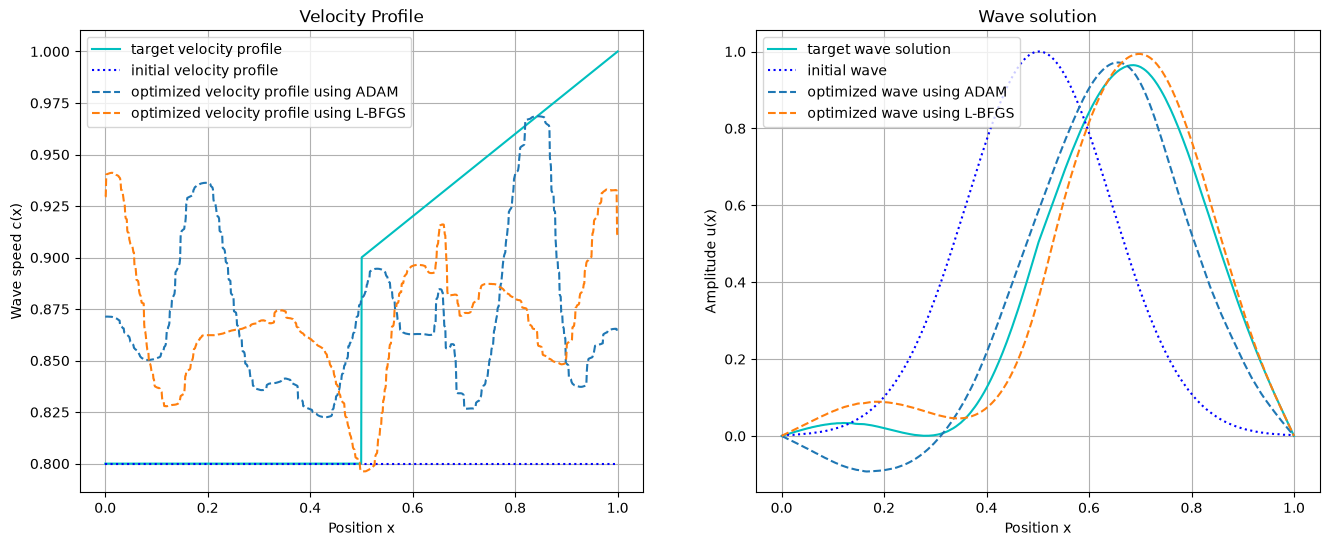

In [43]:
n = 1000
dx = 1.0 / n
x0 = jnp.linspace(0,1.0,n)
dt = 5e-4

@jit
def wave_propagation(params):
    c = params
    C = c*dt/dx

    u0 = jnp.exp(-(5*(x0-0.5))**2)
    u1 = jnp.exp(-(5*(x0-0.5-c*dt))**2)
    u2 = jnp.zeros(n)
    
    a = c**2
    a_half = 0.5 * (a[:-1] + a[1:])

    def step(i, carry):
        u0, u1, u2 = carry
        u1p = jnp.roll(u1, 1)
        u1p = u1p.at[0].set(0)
        u1n = jnp.roll(u1, -1)
        u1n = u1n.at[n-1].set(0)

        u2 = 2 * u1 - u0 + C**2 * (u1p - 2*u1 + u1n)

        flux = a_half * (u1[1:] - u1[:-1]) / dx

        # Flux divergence
        utt = jnp.zeros_like(u1)
        utt = utt.at[1:-1].set(
            (flux[1:] - flux[:-1]) / dx
        )

        # Time integration
        u2 = 2*u1 - u0 + dt**2 * utt

        # Dirichlet boundaries
        u2 = u2.at[0].set(0.0)
        u2 = u2.at[-1].set(0.0)
        
        u0 = u1
        u1 = u2
        return (u0, u1, u2)

    u0, u1, u2 = lax.fori_loop(0, 5000, step, (u0, u1, u2))
    return u0, u1, u2

ctarget = jnp.where(x0<0.5, 0.8, 0.2*x0+0.8)
target_0, target_1, target = wave_propagation(ctarget)

scale = jnp.linalg.norm((target_1-target_0)/dt)

def compute_loss(c):
    u0, u1, u2 = wave_propagation(c)
    velocity = (u1 - u0) / dt
    target_velocity = (target_1 - target_0) / dt
    return jnp.sum((velocity - target_velocity)**2) / jnp.sum(target_velocity**2) + 1e-3 * jnp.sum(jnp.sqrt(jnp.diff(c)**2 + 1e-8))

initial_c = 0.8 * jnp.ones(jnp.size(x0))

def optax_adam(params, niter):
    start_learning_rate = 1e-3
    optimizer = optax.adam(start_learning_rate)
    opt_state = optimizer.init(params)
    for _ in range(niter):
        grads = grad(compute_loss)(params)
        updates, opt_state = optimizer.update(grads, opt_state)
        params = optax.apply_updates(params, updates)
    return params

def jaxopt_lbfgsb(params):
    lower_bound = jnp.full_like(params, 0.1)
    upper_bound = jnp.full_like(params, 1.5)

    solver = jaxopt.LBFGSB(
        fun = compute_loss,
        maxiter = 1000,
        tol = 1e-7,
        maxls = 50,
    )
    result = solver.run(
        init_params = params,
        bounds = (lower_bound, upper_bound)
    )
    return result.params
    
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16,6))
ax1.plot(x0, ctarget, 'c-', label='target velocity profile')
ax1.plot(x0, initial_c, 'b:', label='initial velocity profile')
ax2.plot(x0, target, 'c-', label='target wave solution')
ax2.plot(x0, wave_propagation(initial_c)[2], 'b:', label='initial wave')

for i in range(2):
    if i == 0:
        method = 'ADAM'
        result = optax_adam(initial_c, 1000)
    else:
        method = 'L-BFGS'
        result = jaxopt_lbfgsb(initial_c)
    print(f'The current method is: {method}')
    print(f"initial loss: {compute_loss(initial_c):.6e}")
    print(f"final loss: {compute_loss(result):.6e}")
    
    print(f"The squared root mean error in the velocity profile using {method} is: {jnp.sqrt(jnp.mean((result - ctarget)**2))}")
    ax1.plot(x0, result, '--', label=f'optimized velocity profile using {method}')
    ax2.plot(x0, wave_propagation(result)[2], '--', label=f'optimized wave using {method}')
    
ax1.set_xlabel('Position x')
ax1.set_ylabel('Wave speed c(x)')
ax1.set_title('Velocity Profile')
ax1.grid()
ax1.legend()
    
ax2.set_xlabel('Position x')
ax2.set_ylabel('Amplitude u(x)')
ax2.set_title('Wave solution')
ax2.legend()
ax2.grid()
plt.show()